# 06. Качество и чувствительность погодного покрытия шести аэропортов

## 1. Область анализа и воспроизводимость

Объединены первый и расширенный пилоты: EGCC/EGLL/LFPG и EDDF/EHAM/LEMD,
полные январь и июль 2019 года по C40 UTC. Исследуются основные поля
сообщений с замечаниями, интервалы наблюдений и чувствительность к задержке.
Предполагаемые задержки 0/5/10/15 минут не подтверждают фактическую доступность.
Состав станций различается; сравнение этапов описательное.
[Протокол расширения](04_expansion_protocol.ipynb) ·
[Результаты расширения](05_expansion_coverage_and_decoding.ipynb).


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))

expanded=json.loads((R/'08_pilot_manifest.json').read_text(encoding='utf8'))
assert expanded['input_sha256']==manifest['input_sha256']
for source in expanded['downloads']:
    assert sha(DATA/'raw'/f"{source['airport']}_{source['month']}.csv")==source['sha256']
total_rows=manifest['rows']+expanded['rows']
total_go_arounds=manifest['go_arounds']+expanded['go_arounds']
assert total_rows==171125 and total_go_arounds==508


## 2. Верификация основных полей сообщений с замечаниями

Для каждого сообщения отдельно проверяется префикс до единственной Q/A-группы
и согласованность основных погодных полей с сохраненным разбором. Все исходные
тексты и прежние флаги качества сохраняются. Флаг проверки префикса не означает
валидность полного сообщения или наличие каждого числового значения.


In [2]:
from decode_metar import decode, split_sections, PRESSURE, TEMPERATURE
reports = pd.concat([pd.read_parquet(DATA/'04_decoded_reports.parquet'),pd.read_parquet(DATA/'09_decoded_reports.parquet')],ignore_index=True)
events = pd.concat([pd.read_parquet(DATA/'03_pilot_matches.parquet'),pd.read_parquet(DATA/'08_pilot_matches.parquet')],ignore_index=True)
assert events.source_row.is_unique
protected = {p:sha(p) for p in [DATA/'04_decoded_reports.parquet', DATA/'04_pilot_features.parquet', DATA/'03_pilot_matches.parquet',DATA/'08_pilot_matches.parquet',DATA/'09_decoded_reports.parquet',DATA/'09_pilot_features.parquet']}
fields = [f for f in reports.columns if f.startswith(('wind_','visibility_','cloud_',
    'present_weather_','qnh_','vertical_visibility_')) or f in ['temperature_token',
    'temperature_c','dewpoint_c','cavok','gust_group_reported',
    'cumulonimbus_reported','towering_cumulus_reported']]
def same(a,b):
    if a is None or (isinstance(a,float) and np.isnan(a)):
        return b is None or (isinstance(b,float) and np.isnan(b))
    return a == b
def audit_core(raw,station,stamp,original):
    observed = split_sections(raw)[0]
    tokens = observed.split()
    pressure = [i for i,t in enumerate(tokens) if PRESSURE.fullmatch(t)]
    if len(pressure) != 1:
        return False, '', 'qnh_missing_or_multiple'
    end = pressure[0]
    temperatures = [t for t in tokens[:end] if TEMPERATURE.fullmatch(t)]
    if len(temperatures) != 1:
        return False, '', 'temperature_missing_or_multiple'
    prefix = ' '.join(tokens[:end+1])
    checked = decode(prefix,station,stamp.to_pydatetime())
    changed = [f for f in fields if not same(original[f],checked[f])]
    ok = checked['decoded_candidate'] and not changed
    return ok, prefix, ('value_disagreement:'+','.join(changed) if changed else checked['decode_issues'])
audits = [audit_core(row.metar,row.station,row.metar_utc,row._asdict())
          for row in reports.itertuples(index=False)]
reports[['core_validated','core_prefix','core_issues']] = pd.DataFrame(audits,index=reports.index)
assert len(reports)==18439 and reports.metar_id.is_unique
residual = reports.loc[~reports.decoded_candidate,
    ['metar_id','station','metar_utc','metar','core_prefix','core_validated','core_issues']]
readable_table(residual)
residual.to_csv(R/'10_core_residual_audit.csv',index=False)
display(reports.groupby(['decoded_candidate','core_validated']).size().rename('reports').reset_index())

fields_table=pd.DataFrame({'Проверяемое поле':fields})
display(fields_table)
affected=events.merge(reports[['metar_id','station','metar_utc','metar','core_validated']].rename(columns={'station':'airport'}),
    on=['airport','metar_utc','metar'],how='left',validate='many_to_one')
assert len(affected)==total_rows
effect=affected.groupby('metar_id').agg(matched_rows=('source_row','size'),matched_go_arounds=('GoA','sum')).reset_index()
residual=residual.merge(effect,on='metar_id',how='left',validate='one_to_one')
residual[['matched_rows','matched_go_arounds']]=residual[['matched_rows','matched_go_arounds']].fillna(0).astype(int)
residual.to_csv(R/'10_core_residual_audit.csv',index=False)
display(residual[['station','metar_utc','core_validated','core_issues','matched_rows','matched_go_arounds']])


metar_id,station,metar_utc,metar,core_prefix,core_validated,core_issues
dd288f08c26c9270b99500b582e1872b684f608a5064fae21670c14bc2028770,EGCC,2019-01-22 10:50:00+00:00,EGCC 221050Z VRB03KT 9999 BKN015CB 02/00 Q1000 2000 SHSN TSGS BKN004,EGCC 221050Z VRB03KT 9999 BKN015CB 02/00 Q1000,True,
71687e2f07947e62198dae234e7f901d05b328c01a761ca7662fb05061d74cbd,EGLL,2019-01-16 15:20:00+00:00,EGLL 161520Z AUTO 23009KT 8000 -RA SCT014/// SCT018/// BKN023/// //////CB 10/08 Q1001 3000 SHRA TEMPO BKN014,EGLL 161520Z AUTO 23009KT 8000 -RA SCT014/// SCT018/// BKN023/// //////CB 10/08 Q1001,True,
1c3555165071f9f7ba09339ae088bd17a3454de213a70ec66d0ea91a0c477761,LFPG,2019-01-07 19:00:00+00:00,LFPG 071900Z 23010KT 8000 FEW007 BKN024 TEMPO BKN007,,False,qnh_missing_or_multiple
ee2b29c5c8f7ced489343c3e7b069073da5e6d0a8ef223f27db7b4e126279d4d,LFPG,2019-01-30 00:30:00+00:00,LFPG 300030Z 34008KT 1800 SN BR FEW003 BKN005 BKN012 00/M00 Q0989 ///// TEMPO 0800 SN BKN003,LFPG 300030Z 34008KT 1800 SN BR FEW003 BKN005 BKN012 00/M00 Q0989,True,
4f283ab6656bed4e18b569b69450e0614ca95dc1f76dd9617048eca8f6c9a2bc,LFPG,2019-01-30 03:00:00+00:00,LFPG 300300Z 31010KT 1300 R27L/1900D R09R/1900U R26R/P2000 R08L/P2000 R26L/P2000 R08R/P2000 R27R/P2000 R09L/P2000 SN FEW002 BKN003 00/M00 Q0990 ///// TEMPO 0800 SN BKN003,LFPG 300300Z 31010KT 1300 R27L/1900D R09R/1900U R26R/P2000 R08L/P2000 R26L/P2000 R08R/P2000 R27R/P2000 R09L/P2000 SN FEW002 BKN003 00/M00 Q0990,True,
83c3abe5abdecaeca70126c3ec6988937ea5576a00e3e13cf6bcf3c2d9bfecae,LFPG,2019-01-30 04:00:00+00:00,LFPG 300400Z 31014KT 2000 -SN BR FEW003 BKN004 00/M00 Q0991 R26/5940 R27L/59//42 TEMPO 0800 SN BKN003,LFPG 300400Z 31014KT 2000 -SN BR FEW003 BKN004 00/M00 Q0991,True,
7618fae690c4a4f69da3f1dfd671774d228c3fe901901a5a8a762c03c9c66ce5,LFPG,2019-01-30 04:30:00+00:00,LFPG 300430Z 32023KT 3000 -SN BR SCT006 BKN008 00/00 Q0991 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300430Z 32023KT 3000 -SN BR SCT006 BKN008 00/00 Q0991,True,
ab686ef5862c523a38fdbabccf5dabd693478905761da8692fa8c660429d9cfb,LFPG,2019-01-30 05:00:00+00:00,LFPG 300500Z 31020KT 6000 -RASN BKN011 BKN017 01/00 Q0992 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300500Z 31020KT 6000 -RASN BKN011 BKN017 01/00 Q0992,True,
46f5abe5dc88bf3dad7081b931c2b0302620782908f5c5e4071f5e616f198b4c,LFPG,2019-01-30 05:30:00+00:00,LFPG 300530Z 30017KT 8000 -RASN BKN016 SCT036 01/M00 Q0993 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300530Z 30017KT 8000 -RASN BKN016 SCT036 01/M00 Q0993,True,
dbf88f96fce0458e76c656f28de9a06f8dcaeaecf9bf762f99f776f533621c4c,LFPG,2019-01-30 06:00:00+00:00,LFPG 300600Z 30015KT 9000 BKN010 SCT017 01/00 Q0994 R26/5940 R27L/59//42 R27R/590335 NOSIG,LFPG 300600Z 30015KT 9000 BKN010 SCT017 01/00 Q0994,True,


,decoded_candidate,core_validated,reports
0,False,False,1
1,False,True,11
2,True,True,18427


,Проверяемое поле
0,wind_token
1,wind_direction_token
2,wind_unit
3,wind_speed_raw
4,wind_speed_relation
...,...
39,dewpoint_c
40,qnh_token
41,qnh_unit
42,qnh_raw


,station,metar_utc,core_validated,core_issues,matched_rows,matched_go_arounds
0,EGCC,2019-01-22 10:50:00+00:00,True,,6,0
1,EGLL,2019-01-16 15:20:00+00:00,True,,4,0
2,LFPG,2019-01-07 19:00:00+00:00,False,qnh_missing_or_multiple,9,0
3,LFPG,2019-01-30 00:30:00+00:00,True,,0,0
4,LFPG,2019-01-30 03:00:00+00:00,True,,2,0
5,LFPG,2019-01-30 04:00:00+00:00,True,,12,3
6,LFPG,2019-01-30 04:30:00+00:00,True,,9,0
7,LFPG,2019-01-30 05:00:00+00:00,True,,12,0
8,LFPG,2019-01-30 05:30:00+00:00,True,,14,0
9,LFPG,2019-01-30 06:00:00+00:00,True,,13,0


## 3. Анализ записей LEMD с давностью METAR 60–90 минут

Для каждого C40 приводятся предыдущая и следующая временные отметки архива
и интервал между ними. Следующее сообщение используется только для диагностики
интервала и не участвует в погодных признаках на C40. Интервал между строками
архива не доказывает отсутствие передачи наблюдения метеостанцией.


source_row,airport,month,GoA,C40_CROSS_TIME,metar_utc,age_minutes,next_archive_observation_utc,archive_interval_minutes,status
29332,LEMD,2019-01,False,2019-01-06 16:31:26+00:00,2019-01-06 15:30:00+00:00,61.433333,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29339,LEMD,2019-01,False,2019-01-06 16:32:07+00:00,2019-01-06 15:30:00+00:00,62.116667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29367,LEMD,2019-01,False,2019-01-06 16:36:01+00:00,2019-01-06 15:30:00+00:00,66.016667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29352,LEMD,2019-01,False,2019-01-06 16:38:03+00:00,2019-01-06 15:30:00+00:00,68.050000,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29372,LEMD,2019-01,False,2019-01-06 16:41:07+00:00,2019-01-06 15:30:00+00:00,71.116667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29425,LEMD,2019-01,False,2019-01-06 16:46:35+00:00,2019-01-06 15:30:00+00:00,76.583333,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29395,LEMD,2019-01,False,2019-01-06 16:46:37+00:00,2019-01-06 15:30:00+00:00,76.616667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29435,LEMD,2019-01,False,2019-01-06 16:51:37+00:00,2019-01-06 15:30:00+00:00,81.616667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29441,LEMD,2019-01,False,2019-01-06 16:53:19+00:00,2019-01-06 15:30:00+00:00,83.316667,2019-01-06 17:00:00+00:00,90.0,older_than_60min
29448,LEMD,2019-01,False,2019-01-06 16:54:08+00:00,2019-01-06 15:30:00+00:00,84.133333,2019-01-06 17:00:00+00:00,90.0,older_than_60min


,metar_utc,next_archive_observation_utc,archive_interval_minutes,affected_rows,first_c40,last_c40
0,2019-01-06 15:30:00+00:00,2019-01-06 17:00:00+00:00,90.0,14,2019-01-06 16:31:26+00:00,2019-01-06 16:58:44+00:00


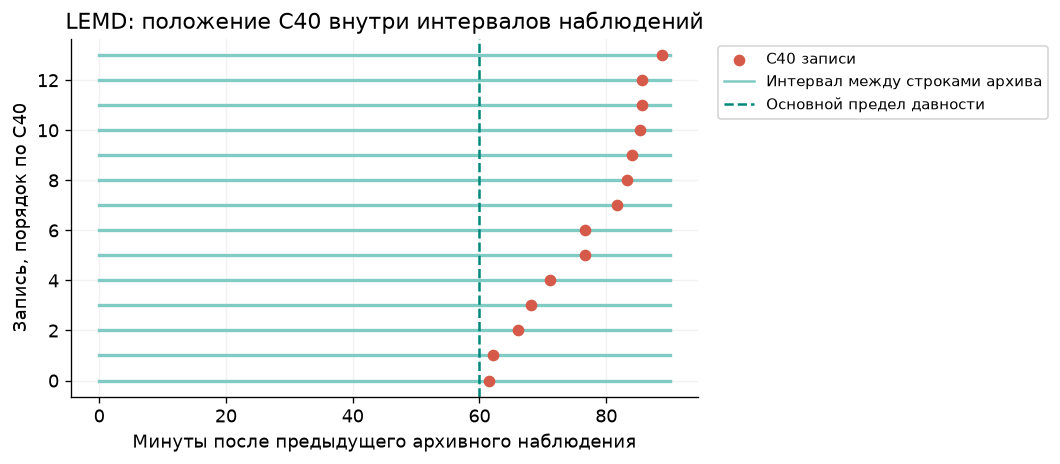

In [3]:
aged=events.loc[events.airport.isin(['EDDF','EHAM','LEMD'])&events.age_minutes.gt(60)&events.age_minutes.le(90)].copy()
assert len(aged)==14 and aged.airport.eq('LEMD').all() and not aged.GoA.any()
times=reports.loc[reports.station.eq('LEMD')&reports.archive_month.eq('2019-01'),'metar_utc'].drop_duplicates().sort_values()
following=[]
for stamp in aged.C40_CROSS_TIME:
    later=times.loc[times.gt(stamp)]
    following.append(later.iloc[0] if len(later) else pd.NaT)
aged['next_archive_observation_utc']=following
aged['archive_interval_minutes']=(aged.next_archive_observation_utc-aged.metar_utc).dt.total_seconds()/60
columns=['source_row','airport','month','GoA','C40_CROSS_TIME','metar_utc','age_minutes',
    'next_archive_observation_utc','archive_interval_minutes','status']
readable_table(aged[columns].sort_values('C40_CROSS_TIME'))
aged[columns].to_csv(R/'10_lemd_aged_records.csv',index=False)
intervals=aged.groupby(['metar_utc','next_archive_observation_utc','archive_interval_minutes']).agg(
    affected_rows=('source_row','size'),first_c40=('C40_CROSS_TIME','min'),last_c40=('C40_CROSS_TIME','max')).reset_index()
display(intervals)
fig,ax=plt.subplots(figsize=(9,4))
for i,row in enumerate(aged.sort_values('C40_CROSS_TIME').itertuples()):
    ax.plot([0,row.archive_interval_minutes],[i,i],color=LIGHT_GREEN,linewidth=2)
    ax.scatter(row.age_minutes,i,color=CORAL,zorder=3)
ax.scatter([],[],color=CORAL,label='C40 записи')
ax.plot([],[],color=LIGHT_GREEN,label='Интервал между строками архива')
ax.axvline(60,color=GREEN,linestyle='--',label='Основной предел давности')
ax.set(xlabel='Минуты после предыдущего архивного наблюдения',ylabel='Запись, порядок по C40',
    title='LEMD: положение C40 внутри интервалов наблюдений')
ax.legend(loc='upper left',bbox_to_anchor=(1.02,1),fontsize=9)
save('17_lemd_archive_intervals')


## 4. Повторный выбор METAR при предполагаемой задержке публикации

Выбирается последнее наблюдение с `observation_time + latency < C40`.
Давность считается от наблюдения. Последнее сообщение не пропускается из-за
замечаний качества или COR. После выбора проверяются предел давности и флаги.
При этом COR может смениться более старым сообщением без COR, поэтому покрытие
без COR не обязано монотонно уменьшаться при увеличении задержки.


In [4]:
rows = []
zero_parts = []
for latency in [0,5,10,15]:
    for (airport,month),part in events.groupby(['airport','month']):
        right = reports.loc[reports.station.eq(airport) & reports.archive_month.eq(month)].copy()
        right['ambiguous'] = right.groupby('metar_utc').metar.transform('nunique').gt(1)
        right = right.drop_duplicates('metar_utc').sort_values('metar_utc')
        right['assumed_available_utc'] = right.metar_utc+pd.Timedelta(minutes=latency)
        joined = pd.merge_asof(part[['source_row','C40_CROSS_TIME','GoA']].sort_values('C40_CROSS_TIME'),
            right[['assumed_available_utc','metar_utc','metar_id','decoded_candidate','core_validated','correction_reported','ambiguous']],
            left_on='C40_CROSS_TIME',right_on='assumed_available_utc',direction='backward',allow_exact_matches=False)
        joined['age'] = (joined.C40_CROSS_TIME-joined.metar_utc).dt.total_seconds()/60
        assert joined.loc[joined.metar_utc.notna(),'age'].gt(latency).all()
        if latency==0:
            zero_parts.append(joined[['source_row','metar_utc']])
        for limit in [30,60,90]:
            timely = joined.age.le(limit) & ~joined.ambiguous.eq(True)
            for quality in ['decoded_candidate','core_validated']:
                for exclude_cor in [False,True]:
                    candidate = timely & joined[quality].eq(True)
                    if exclude_cor:
                        candidate &= ~joined.correction_reported.eq(True)
                    for label in [False,True]:
                        group = joined.GoA.eq(label)
                        rows.append(dict(airport=airport,month=month,latency_minutes=latency,
                            maximum_age_minutes=limit,quality=quality,exclude_cor=exclude_cor,GoA=label,
                            total=int(group.sum()),candidates=int((group & candidate).sum())))
scenarios = pd.DataFrame(rows)
scenarios['coverage_percent'] = 100*scenarios.candidates/scenarios.total
scenarios.to_csv(R/'10_availability_scenarios.csv',index=False)
baseline = pd.concat(zero_parts).set_index('source_row').sort_index()
pd.testing.assert_series_equal(baseline.metar_utc,events.set_index('source_row').sort_index().metar_utc)
summary = scenarios.groupby(['latency_minutes','maximum_age_minutes','quality','exclude_cor','GoA'])[['total','candidates']].sum().reset_index()
summary['coverage_percent'] = 100*summary.candidates/summary.total
display(summary.loc[summary.maximum_age_minutes.eq(60)])

scenarios['stage']=np.where(scenarios.airport.isin(['EGCC','EGLL','LFPG']),'Первый пилот','Расширенный пилот')
scenarios.to_csv(R/'10_availability_scenarios.csv',index=False)
by_stage=scenarios.groupby(['stage','latency_minutes','maximum_age_minutes','quality','exclude_cor','GoA'])[['total','candidates']].sum().reset_index()
by_stage['coverage_percent']=100*by_stage.candidates/by_stage.total
by_stage.to_csv(R/'10_stage_comparison.csv',index=False)
display(by_stage.loc[by_stage.maximum_age_minutes.eq(60)&by_stage.quality.eq('core_validated')&by_stage.exclude_cor.eq(True)])


,latency_minutes,maximum_age_minutes,quality,exclude_cor,GoA,total,candidates,coverage_percent
8,0,60,core_validated,False,False,170617,170594,99.986520
9,0,60,core_validated,False,True,508,508,100.000000
10,0,60,core_validated,True,False,170617,170458,99.906809
11,0,60,core_validated,True,True,508,507,99.803150
12,0,60,decoded_candidate,False,False,170617,170503,99.933184
...,...,...,...,...,...,...,...,...
83,15,60,core_validated,True,True,508,508,100.000000
84,15,60,decoded_candidate,False,False,170617,170431,99.890984
85,15,60,decoded_candidate,False,True,508,505,99.409449
86,15,60,decoded_candidate,True,False,170617,170309,99.819479


,stage,latency_minutes,maximum_age_minutes,quality,exclude_cor,GoA,total,candidates,coverage_percent
10,Первый пилот,0,60,core_validated,True,False,76434,76289,99.810294
11,Первый пилот,0,60,core_validated,True,True,307,306,99.674267
34,Первый пилот,5,60,core_validated,True,False,76434,76287,99.807677
35,Первый пилот,5,60,core_validated,True,True,307,307,100.000000
58,Первый пилот,10,60,core_validated,True,False,76434,76281,99.799827
59,Первый пилот,10,60,core_validated,True,True,307,307,100.000000
82,Первый пилот,15,60,core_validated,True,False,76434,76281,99.799827
83,Первый пилот,15,60,core_validated,True,True,307,307,100.000000
106,Расширенный пилот,0,60,core_validated,True,False,94183,94169,99.985135
107,Расширенный пилот,0,60,core_validated,True,True,201,201,100.000000


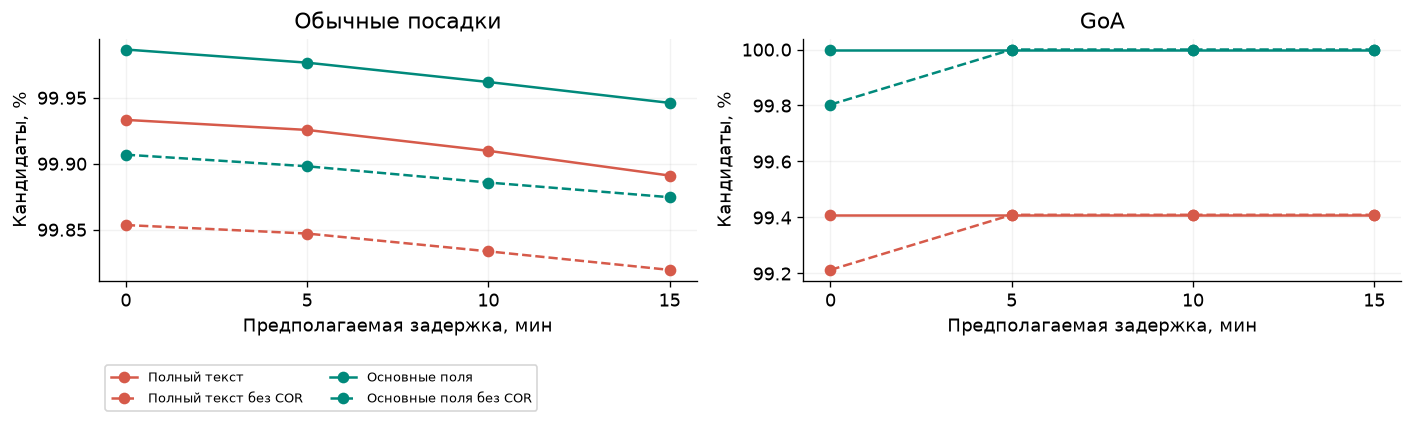

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for quality,color in [('decoded_candidate',CORAL),('core_validated',GREEN)]:
        subset=summary.loc[summary.maximum_age_minutes.eq(60)&summary.GoA.eq(label)&summary.quality.eq(quality)]
        for exclude,style in [(False,'-'),(True,'--')]:
            series=subset.loc[subset.exclude_cor.eq(exclude)].sort_values('latency_minutes')
            ax.plot(series.latency_minutes,series.coverage_percent,style,marker='o',color=color,
                label=('Полный текст' if quality=='decoded_candidate' else 'Основные поля')+(' без COR' if exclude else ''))
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Кандидаты, %',xticks=[0,5,10,15])
axes[0].legend(fontsize=8,loc='upper left',bbox_to_anchor=(0,-.32),ncol=2)
save('18_combined_latency_quality')


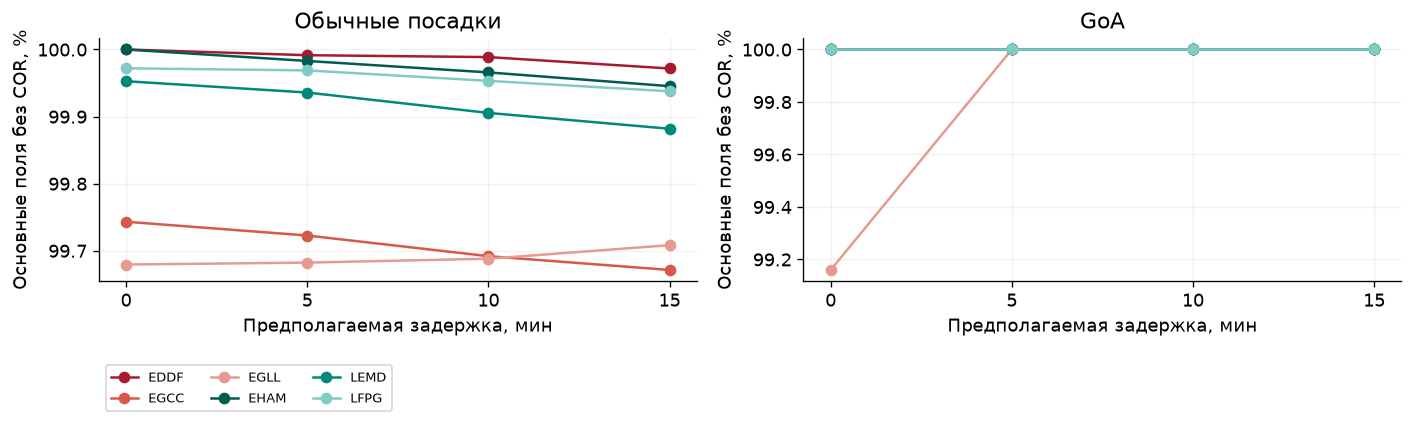

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for airport,color in zip(sorted(events.airport.unique()),['#A51C30','#D65A4A','#E69A90','#005B50','#00897B','#80CBC4']):
        subset=scenarios.loc[scenarios.maximum_age_minutes.eq(60)&scenarios.GoA.eq(label)&
            scenarios.quality.eq('core_validated')&scenarios.exclude_cor.eq(True)&scenarios.airport.eq(airport)]
        series=subset.groupby('latency_minutes')[['total','candidates']].sum()
        ax.plot(series.index,100*series.candidates/series.total,marker='o',label=airport,color=color)
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Основные поля без COR, %',xticks=[0,5,10,15])
axes[0].legend(loc='upper left',bbox_to_anchor=(0,-.32),ncol=3,fontsize=8)
save('19_combined_latency_airports')


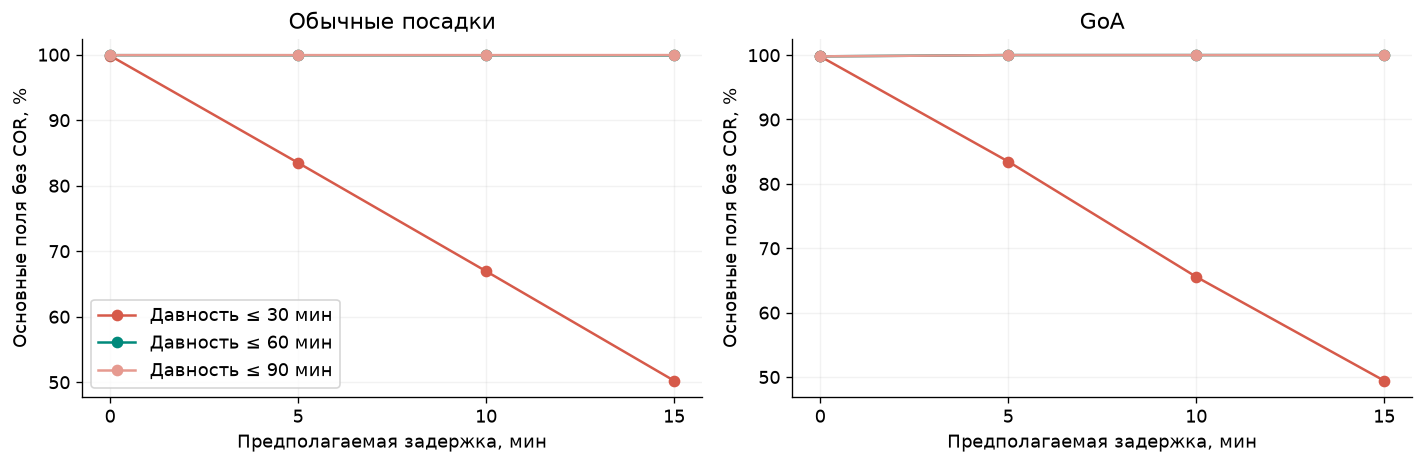

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for limit in [30,60,90]:
        subset=summary.loc[summary.maximum_age_minutes.eq(limit)&summary.GoA.eq(label)&
            summary.quality.eq('core_validated')&summary.exclude_cor.eq(True)].sort_values('latency_minutes')
        ax.plot(subset.latency_minutes,subset.coverage_percent,marker='o',label=f'Давность ≤ {limit} мин')
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Основные поля без COR, %',xticks=[0,5,10,15])
axes[0].legend()
save('20_combined_latency_age_limits')


## 5. Сравнение этапов и условия дальнейшего расширения

Основные поля оцениваются отдельно от полного текста: успешный разбор префикса
не исправляет группы состояния ВПП или сдвига ветра. Пропуски остаются пропусками.
Сравнение этапов не оценивает эффект аэропорта или сезонности.

Перед расширением на остальные станции требуется фиксированный перечень
станций и периодов, проверка идентичности станции, сохранение сырого ответа и
SHA256, контроль кратности и меток, а также полный учет неизвестных кодов,
неоднозначных временных отметок и пробелов покрытия. Новая неподдерживаемая
единица или код требует отдельной проверки до использования признака.
Порог 60 минут остается исследовательским; результаты 30/90 минут и задержек
представляются отдельно, без подбора порога по сохранению GoA.

Для обучения отдельно должны быть определены доступность аэропорта к C40,
обработка пропусков и временное разделение данных. Историческое время получения
METAR пока неизвестно. Массовая загрузка и обучение в этом ноутбуке не выполняются.


In [8]:
for path,digest in protected.items():
    assert sha(path)==digest
assert len(events)==total_rows and int(events.GoA.sum())==total_go_arounds
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015 02/00 Q1000 Q1001','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015 Q1000','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
display(Markdown('**Проверено:** исходные файлы неизменны; нулевая задержка воспроизводит прежний выбор METAR; неоднозначный QNH и отсутствующие основные группы не принимаются.'))

# Неподдержанная группа внутри основных полей должна блокировать префикс.
bad='EHAM 180455Z 17003KT INVALID CAVOK M02/M02 Q1017'
original=decode(bad,'EHAM',pd.Timestamp('2019-01-18T04:55Z').to_pydatetime())
assert not audit_core(bad,'EHAM',pd.Timestamp('2019-01-18T04:55Z'),original)[0]
good='EHAM 180455Z 17003KT CAVOK M02/M02 Q1017 06/1///95 NOSIG'
original=decode(good,'EHAM',pd.Timestamp('2019-01-18T04:55Z').to_pydatetime())
assert audit_core(good,'EHAM',pd.Timestamp('2019-01-18T04:55Z'),original)[0]
changed=dict(original,wind_speed_kt=999)
assert not audit_core(good,'EHAM',pd.Timestamp('2019-01-18T04:55Z'),changed)[0]
import unittest,test_decode_metar
outcome=unittest.TextTestRunner(stream=sys.stdout,verbosity=1).run(unittest.defaultTestLoader.loadTestsFromModule(test_decode_metar))
assert outcome.wasSuccessful()
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==manifest['input_sha256']
overview={'rows':total_rows,'go_arounds':total_go_arounds,'reports':len(reports),
    'residual_reports':len(residual),'core_validated_residual_reports':int(residual.core_validated.sum()),
    'aged_expansion_rows':len(aged),'rows_deleted':0,'input_unchanged':True,
    'previous_files_unchanged':all(sha(p)==d for p,d in protected.items()),
    'availability_verified':False,'training_executed':False}
(R/'10_quality_manifest.json').write_text(json.dumps(overview,indent=2)+'\n',encoding='utf8')
display(pd.DataFrame([overview]).T)


**Проверено:** исходные файлы неизменны; нулевая задержка воспроизводит прежний выбор METAR; неоднозначный QNH и отсутствующие основные группы не принимаются.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 12 tests in 0.006s

OK


,0
rows,171125
go_arounds,508
reports,18439
residual_reports,12
core_validated_residual_reports,11
aged_expansion_rows,14
rows_deleted,0
input_unchanged,True
previous_files_unchanged,True
availability_verified,False
